# 02｜第 1 節：郵件分類、決策樹與 SVM

**必做只有 4 組練習。** 每組先閱讀 Markdown 程式範例，再把程式輸入下方的空白 Code Cell。

**必做流程：讀取 CSV → 選擇 X／y 並切分 → One-Hot＋標準化 → 決策樹 `fit()`、`predict()`、評估。**

SVM、詳細分類指標及圖表放在後面的 **Optional（選做）**；程式已經寫好，直接執行即可。

請先將 `02_校園郵件分類_500筆.csv` 放在 Colab `/content`，或 Notebook 的工作目錄。本節可以獨立執行。


In [1]:
# Import all libraries used in this notebook.
# 一次匯入本份 Notebook 需要的套件。
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay

# Use a Chinese font where it is installed.
# 如果電腦有安裝微軟正黑體，就使用這個字型。
matplotlib.rc('font', family='Microsoft JhengHei')

# Fix minus signs on chart axes.
# 避免負號顯示為方框。
matplotlib.rcParams['axes.unicode_minus'] = False

# Use the built-in font in Google Colab.
# Colab 通常沒有微軟正黑體，因此使用內建字型。
if Path('/content').exists():
    matplotlib.rc('font', family='DejaVu Sans')

## 資料集欄位（500 封模擬校園郵件）

| 欄位 | 內容 | 用途 |
|---|---|---|
| `email_id` | 郵件編號 | 識別用，不放入模型 |
| `link_count` | 網址連結數量 | 數值特徵 X |
| `urgent_words` | 急迫用語出現次數 | 數值特徵 X |
| `exclamation_count` | 驚嘆號數量 | 數值特徵 X |
| `sender_known` | 是否為已知寄件者（1＝是） | 0／1 特徵 X |
| `email_type` | 郵件類型 | 類別特徵 X（One-Hot） |
| `is_spam` | 1＝垃圾郵件；0＝正常郵件 | 正確答案 y |

本份資料 **沒有缺漏值**，不需要使用 `fillna()`。兩節都使用這 500 筆資料，但可以各自獨立執行。


## 必做：4 組練習


### 練習 1／4｜讀取資料

先查看電子郵件資料長什麼樣子。

**參考程式：**

```python
# Read the CSV file.
# 讀取 CSV 檔案。
df = pd.read_csv('02_校園郵件分類_500筆.csv')

# View the first five emails.
# 查看前五筆郵件資料。
display(df.head())
```

In [ ]:
# 請在此處根據範例練習程式碼



,email_id,link_count,urgent_words,exclamation_count,sender_known,email_type,is_spam
0,E001,1,1,0,0,校務公告,0
1,E002,2,0,0,1,社團活動,0
2,E003,0,3,0,0,課程通知,0
3,E004,1,1,1,1,課程通知,0
4,E005,1,1,0,1,課程通知,0


### 練習 2／4｜選擇 X／y，切分資料

`is_spam` 是答案 y，郵件編號不拿來訓練。`stratify=y` 讓兩組有相近的垃圾郵件比例。

**參考程式：**

```python
# Separate the input features and correct answers.
# 區分輸入特徵 X 與正確答案 y。
X = df.drop(columns=['email_id', 'is_spam'])
y = df['is_spam']

# Keep 20% of the data for testing.
# 保留 20% 的郵件作為測試資料。
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.2, 
    stratify=y, 
    random_state=42
)

# Show the number of training and test emails.
# 顯示訓練集與測試集各有幾封郵件。
print('Train:', len(X_train), 'Test:', len(X_test))
```

In [ ]:
# 請在此處根據範例練習程式碼



Train: 400 Test: 100


### 練習 3／4｜One-Hot＋數值標準化

這份資料**沒有缺漏值**，所以不需要補值。先將 `email_type` 變成 0／1，再標準化三個計數欄位。`sender_known` 原本就是 0／1，不需要再標準化。

**參考程式：**

```python
# Choose the three count features to standardize.
# 指定要標準化的三個計數欄位。
num_cols = ['link_count', 'urgent_words', 'exclamation_count']

# Change email types into 0/1 columns.
# 將郵件類型轉成 0／1 欄位。
X_train_ready = pd.get_dummies(X_train, dtype=int)
X_test_ready = pd.get_dummies(X_test, dtype=int)

# Create the standardization tool.
# 建立標準化工具。
scaler = StandardScaler()

# Learn scaling from training data, then apply it to test data.
# 只從訓練集學標準化規則，再套用至測試集。
X_train_ready[num_cols] = scaler.fit_transform(X_train_ready[num_cols])
X_test_ready[num_cols] = scaler.transform(X_test_ready[num_cols])

# Preview the completed input features.
# 檢視處理完成的前五筆輸入特徵。
display(X_train_ready.head())
```

In [ ]:
# 請在此處根據範例練習程式碼



,link_count,urgent_words,exclamation_count,sender_known,email_type_優惠資訊,email_type_校務公告,email_type_社團活動,email_type_課程通知
105,0.682934,0.044492,0.313717,1,0,1,0,0
424,-1.102514,0.044492,0.313717,1,0,0,0,1
460,3.361105,3.999319,1.404908,0,1,0,0,0
334,-0.209790,2.021905,0.313717,1,0,0,1,0
228,-1.102514,0.044492,-0.777474,1,0,0,0,1


### 練習 4／4｜決策樹：訓練、預測、評估

使用 **Decision Tree** 預測垃圾郵件。`Accuracy` 是整體答對率；`F1` 用來綜合衡量垃圾郵件類別的 Precision 與 Recall。

**參考程式：**

```python
# Train a decision tree model.
# 訓練決策樹分類模型。
model = DecisionTreeClassifier(max_depth=3, random_state=42)
model.fit(X_train_ready, y_train)

# Predict whether the test emails are spam.
# 預測測試資料是否為垃圾郵件。
pred = model.predict(X_test_ready)

# Check the prediction performance.
# 查看分類預測的成效。
print('Accuracy:', round(accuracy_score(y_test, pred), 2))
print('F1:', round(f1_score(y_test, pred), 2))
```

In [ ]:
# 請在此處根據範例練習程式碼



Accuracy: 0.85
F1: 0.55


## 必做完成：你已經做出分類模型

看懂四個關鍵動作：**CSV 資料 → 前處理 → `fit()` 訓練 → `predict()` 預測 → Accuracy／F1 評估**。

接下來全部是 **Optional（選做）**，**只要直接執行 Code Cell，不必手動照寫**。若時間不夠，今天可以停在這裡。


### Optional A｜SVM：換一種分類模型

沿用同一份 `X_train_ready` 和 `X_test_ready`，觀察決策樹與 SVM 的 F1。想比較核函數時，可以把 `kernel='rbf'` 改成 `'linear'` 再執行。


In [ ]:
# Train an SVM model with the same prepared data.
# 使用相同的資料訓練 SVM。
svm = SVC(kernel='rbf')
svm.fit(X_train_ready, y_train)

# Predict the test emails.
# 預測測試郵件。
pred_svm = svm.predict(X_test_ready)

# Compare the two models using F1.
# 使用 F1 比較兩個分類模型。
print('Decision Tree F1:', round(f1_score(y_test, pred), 2))
print('SVM F1:', round(f1_score(y_test, pred_svm), 2))

Decision Tree F1: 0.55
SVM F1: 0.56


### Optional B｜更詳細的分類評估

**Precision**：預測為垃圾郵件時有多準。**Recall**：真正的垃圾郵件抓到多少。混淆矩陣用四個格子呈現判對與判錯的數量。


Precision: 0.69
Recall: 0.45


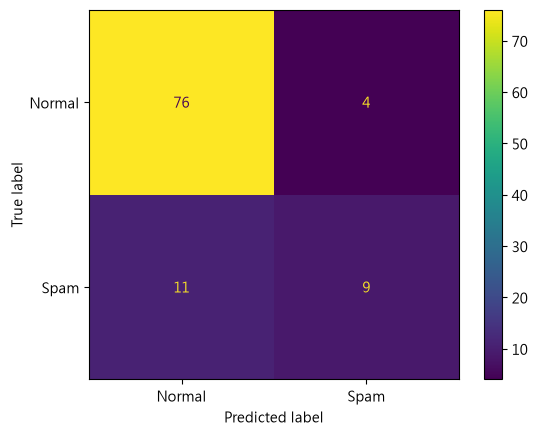

In [7]:
# Show precision and recall for spam emails.
# 查看垃圾郵件的 Precision 與 Recall。
print('Precision:', round(precision_score(y_test, pred), 2))
print('Recall:', round(recall_score(y_test, pred), 2))

# Draw the confusion matrix of the decision tree.
# 畫出決策樹的混淆矩陣。
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=['Normal', 'Spam'])
plt.show()

### Optional C｜為什麼不能只看 Accuracy？

這份資料約有 80% 的郵件是正常郵件。試試看全部猜「正常」，就知道 Accuracy 高不一定能抓到垃圾郵件。


In [8]:
# Predict every test email as normal.
# 假設所有測試郵件都被判定為正常。
always_normal = np.zeros(len(y_test), dtype=int)

# Compare accuracy and recall.
# 比較整體答對率與垃圾郵件的召回率。
print('Accuracy:', round(accuracy_score(y_test, always_normal), 2))
print('Recall:', round(recall_score(y_test, always_normal), 2))

Accuracy: 0.8
Recall: 0.0


### Optional D｜決策樹長什麼樣子？

直接把已經訓練好的 `model` 畫出前兩層，觀察模型如何根據特徵做決定。


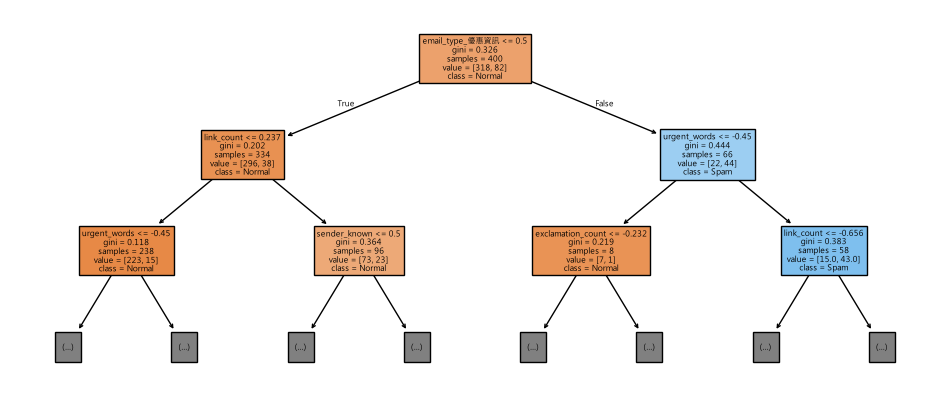

In [9]:
# Draw the first two levels of the trained decision tree.
# 畫出決策樹前兩層的判斷規則。
plt.figure(figsize=(12, 5))
plot_tree(model, feature_names=list(X_train_ready.columns), max_depth=2, filled=True, class_names=['Normal', 'Spam'])
plt.show()

### Optional E｜輸入四封新郵件，預測是否為垃圾郵件

不需要重新訓練。這裡準備四封不同類型的郵件，讓 One-Hot 編碼產生與訓練資料相同的四個類別欄位，可以直接預測。

**注意：** 這是為了入門練習而簡化的範例。若日後只輸入一種或兩種郵件類型，就不一定能直接使用相同寫法。


In [10]:
# Create four example emails.
# 輸入四封不同類型的模擬郵件。
new_data = pd.DataFrame({
    'link_count': [0, 2, 5, 1],
    'urgent_words': [0, 2, 4, 0],
    'exclamation_count': [0, 2, 4, 1],
    'sender_known': [1, 0, 0, 1],
    'email_type': ['校務公告', '社團活動', '優惠資訊', '課程通知']
})

# Encode new email types as 0/1 columns.
# 將新郵件的類別轉成 0／1 欄位。
X_new_ready = pd.get_dummies(new_data, dtype=int)

# Apply the existing scaler to the three count features.
# 對三個計數欄位套用訓練時的標準化規則。
X_new_ready[num_cols] = scaler.transform(X_new_ready[num_cols])

# Predict the four new emails.
# 預測四封新郵件是否為垃圾郵件。
new_data['預測（1=垃圾）'] = model.predict(X_new_ready)

# Display the predictions.
# 顯示四封郵件與預測結果。
display(new_data)

,link_count,urgent_words,exclamation_count,sender_known,email_type,預測（1=垃圾）
0,0,0,0,1,校務公告,0
1,2,2,2,0,社團活動,0
2,5,4,4,0,優惠資訊,1
3,1,0,1,1,課程通知,0


**第 1 節完成。** 核心是完整做出分類模型；SVM 與圖表可依課堂時間自行操作。
